# Highway Networks — implementacja i trening na CIFAR-10

Implementacja na podstawie:
> Srivastava, Greff, Schmidhuber. *Highway Networks*. arXiv:1505.00387

Główna idea: zamiast `y = H(x)` używamy

$$y = H(x)\cdot T(x) + x\cdot (1 - T(x))$$

gdzie `T(x)` to bramka transformacji (sigmoid). Dzięki temu gradient może płynąć przez setki warstw, a sieć uczy się, które warstwy „pomijać”.

**Dane:** CIFAR-10 pobierane przez Hugging Face (szybko, bez wolnego serwera UToronto).

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
import matplotlib.pyplot as plt
import numpy as np
import time
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
torch.manual_seed(42)

Device: cuda


In [2]:
class HighwayFC(nn.Module):
    """W pełni połączona warstwa Highway (Eq. 3 z paperu)."""
    def __init__(self, size, gate_bias_init=-1.0, activation=nn.ReLU):
        super().__init__()
        self.H = nn.Linear(size, size)
        self.T = nn.Linear(size, size)
        self.activation = activation()

        # Sekcja 2.2: ujemny bias bramki => sieć startuje blisko "carry"
        nn.init.constant_(self.T.bias, gate_bias_init)

    def forward(self, x):
        h = self.activation(self.H(x))          # H(x)
        t = torch.sigmoid(self.T(x))            # T(x)
        return h * t + x * (1.0 - t)            # Eq. 3

In [3]:
class HighwayConv2d(nn.Module):
    """Konwolucyjna warstwa Highway. Zero-padding zachowuje wymiar H*W (Sekcja 2.1)."""
    def __init__(self, channels, kernel_size=3, gate_bias_init=-1.0,
                 activation=nn.ReLU):
        super().__init__()
        padding = kernel_size // 2
        self.H = nn.Conv2d(channels, channels, kernel_size, padding=padding)
        self.T = nn.Conv2d(channels, channels, kernel_size, padding=padding)
        self.activation = activation()

        nn.init.constant_(self.T.bias, gate_bias_init)

    def forward(self, x):
        h = self.activation(self.H(x))
        t = torch.sigmoid(self.T(x))
        return h * t + x * (1.0 - t)

In [4]:
class HighwayCIFAR(nn.Module):
    """
    Architektura:
      [stem conv 3x3] -> [N x HighwayConv2d] -> [BN] -> [GAP] -> [Linear]
    Stem (warstwa 'plain') zmienia liczbę kanałów — tak jak w paperze,
    gdzie wymiar musi się zgadzać wewnątrz bloku highway.
    """
    def __init__(self, num_highways=9, channels=64, num_classes=10,
                 gate_bias_init=-1.0):
        super().__init__()
        self.stem = nn.Conv2d(3, channels, kernel_size=3, padding=1)
        self.highways = nn.ModuleList([
            HighwayConv2d(channels, kernel_size=3,
                          gate_bias_init=gate_bias_init)
            for _ in range(num_highways)
        ])
        self.bn = nn.BatchNorm2d(channels)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(channels, num_classes)

    def forward(self, x):
        x = F.relu(self.stem(x))
        for hw in self.highways:
            x = hw(x)
        x = F.relu(self.bn(x))
        x = self.pool(x).flatten(1)
        return self.fc(x)


model = HighwayCIFAR(num_highways=9, channels=64).to(device)
print(f"Parametry: {sum(p.numel() for p in model.parameters())/1e6:.2f} M")

Parametry: 0.67 M


In [5]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD  = (0.2470, 0.2435, 0.2616)

transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

In [6]:
from datasets import load_dataset

class HF_CIFAR10(Dataset):
    """CIFAR-10 z Hugging Face (uoft-cs/cifar10)."""
    def __init__(self, split="train", transform=None):
        self.data = load_dataset("uoft-cs/cifar10", split=split)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]
        image = item["img"]       # PIL.Image
        label = item["label"]
        if self.transform:
            image = self.transform(image)
        return image, label


train_set = HF_CIFAR10(split="train", transform=transform_train)
test_set  = HF_CIFAR10(split="test",  transform=transform_test)

train_loader = DataLoader(train_set, batch_size=128, shuffle=True,
                          num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_set, batch_size=256, shuffle=False,
                          num_workers=2, pin_memory=True)

print(f"Train: {len(train_set)} | Test: {len(test_set)}")

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Train: 50000 | Test: 10000


In [7]:
def train_epoch(model, loader, optimizer, criterion, epoch=1, total_epochs=1,
                log_every=100):
    model.train()
    total_loss, total_correct, total = 0.0, 0, 0
    t0 = time.time()

    pbar = tqdm(loader, desc=f"Epoch {epoch}/{total_epochs}", leave=False,
                dynamic_ncols=True)
    for step, (x, y) in enumerate(pbar, 1):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()

        bs = x.size(0)
        total_loss += loss.item() * bs
        total_correct += (out.argmax(1) == y).sum().item()
        total += bs

        pbar.set_postfix({
            "loss": f"{total_loss/total:.4f}",
            "acc":  f"{100*total_correct/total:.2f}%",
        })

        if step % log_every == 0:
            elapsed = time.time() - t0
            ips = total / elapsed
            print(f"  [Ep {epoch:02d} step {step:4d}/{len(loader)}] "
                  f"loss {total_loss/total:.4f} | acc {100*total_correct/total:.2f}% "
                  f"| {ips:.1f} img/s")

    return total_loss / total, total_correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, total_correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        out = model(x)
        loss = criterion(out, y)
        total_loss += loss.item() * x.size(0)
        total_correct += (out.argmax(1) == y).sum().item()
        total += x.size(0)
    return total_loss / total, total_correct / total

In [8]:
EPOCHS = 30
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1,
                            momentum=0.9, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
best_acc = 0.0
t_start = time.time()

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_epoch(model, train_loader, optimizer, criterion,
                                  epoch=epoch, total_epochs=EPOCHS)
    te_loss, te_acc = evaluate(model, test_loader, criterion)
    scheduler.step()

    history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
    history["test_loss"].append(te_loss);  history["test_acc"].append(te_acc)

    lr_now = optimizer.param_groups[0]["lr"]
    elapsed = time.time() - t_start
    eta = elapsed / epoch * (EPOCHS - epoch)
    marker = ""
    if te_acc > best_acc:
        best_acc = te_acc
        marker = "  ← best"
        torch.save(model.state_dict(), "highway_cifar10_best.pt")

    print(f"Epoch {epoch:02d}/{EPOCHS} | "
          f"train loss {tr_loss:.4f} acc {tr_acc*100:.2f}% | "
          f"test loss {te_loss:.4f} acc {te_acc*100:.2f}% | "
          f"lr {lr_now:.4f} | {elapsed/60:.1f} min (ETA {eta/60:.1f} min){marker}")

print(f"\n✅ Trening zakończony w {(time.time()-t_start)/60:.1f} min. "
      f"Najlepsze test acc: {best_acc*100:.2f}%")

Epoch 1/30:   0%|          | 0/391 [00:00<?, ?it/s]

  [Ep 01 step  100/391] loss 1.9747 | acc 25.87% | 464.8 img/s
  [Ep 01 step  200/391] loss 1.8495 | acc 30.20% | 492.5 img/s
  [Ep 01 step  300/391] loss 1.7636 | acc 33.62% | 499.6 img/s


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79e7b0559800>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in:     <function _MultiProcessingDataLoaderIter.__del__ at 0x79e7b0559800>self._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
        if w.is_alive():self._shutdown_workers()

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    
if w.is_alive():AssertionError
  File "/usr/lib/python3.13/multiprocessing/proce

Epoch 01/30 | train loss 1.6940 acc 36.46% | test loss 1.4798 acc 45.74% | lr 0.0997 | 1.8 min (ETA 53.1 min)  ← best


Epoch 2/30:   0%|          | 0/391 [00:00<?, ?it/s]

...

Epoch 30/30:   0%|          | 0/391 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79e7b0559800>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79e7b0559800>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

  [Ep 30 step  100/391] loss 0.2184 | acc 93.06% | 488.1 img/s
  [Ep 30 step  200/391] loss 0.2206 | acc 92.84% | 497.6 img/s
  [Ep 30 step  300/391] loss 0.2251 | acc 92.76% | 501.2 img/s


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79e7b0559800>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
Exception ignored in:     assert self._parent_pid == os.getpid(), 'can only test a child process'<function _MultiProcessingDataLoaderIter.__del__ at 0x79e7b0559800>

AssertionErrorTraceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
:     self._shutdown_workers()can only test a child process

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 30/30 | train loss 0.2249 acc 92.80% | test loss 0.4042 acc 86.54% | lr 0.0000 | 54.2 min (ETA 0.0 min)  ← best

✅ Trening zakończony w 54.2 min. Najlepsze test acc: 86.54%


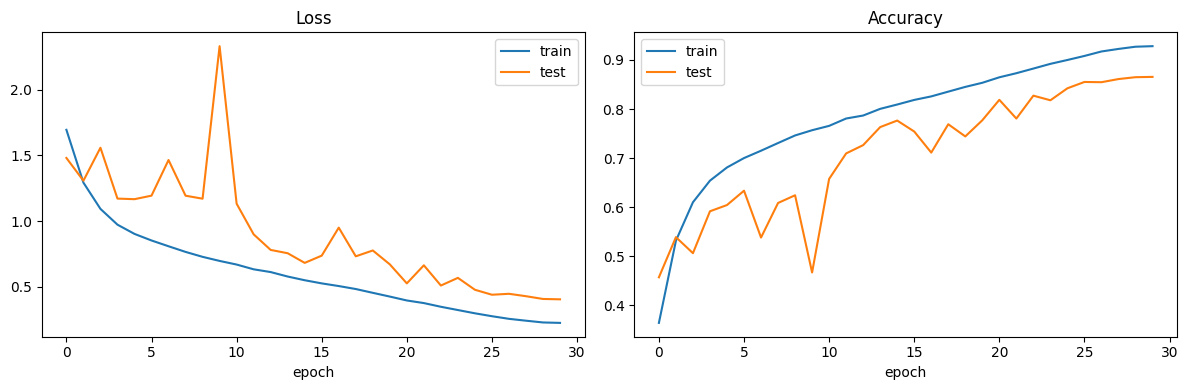

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history["train_loss"], label="train")
ax[0].plot(history["test_loss"],  label="test")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history["train_acc"], label="train")
ax[1].plot(history["test_acc"],  label="test")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

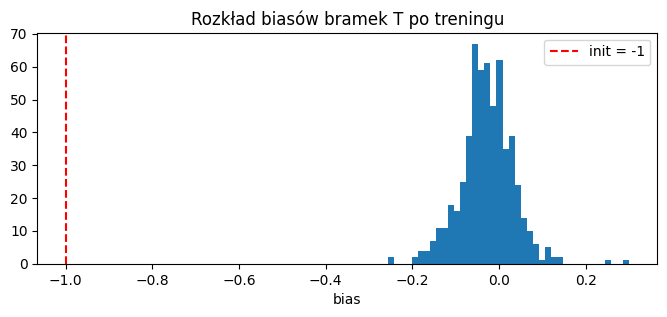

Średni bias po treningu: -0.028


In [10]:
# 1) Rozkład biasów bramek po treningu
biases = [hw.T.bias.detach().cpu().numpy().flatten()
          for hw in model.highways]
all_b = np.concatenate(biases)
plt.figure(figsize=(8, 3))
plt.hist(all_b, bins=40)
plt.axvline(-1.0, color='r', linestyle='--', label='init = -1')
plt.title("Rozkład biasów bramek T po treningu")
plt.xlabel("bias"); plt.legend(); plt.show()
print(f"Średni bias po treningu: {all_b.mean():.3f}")

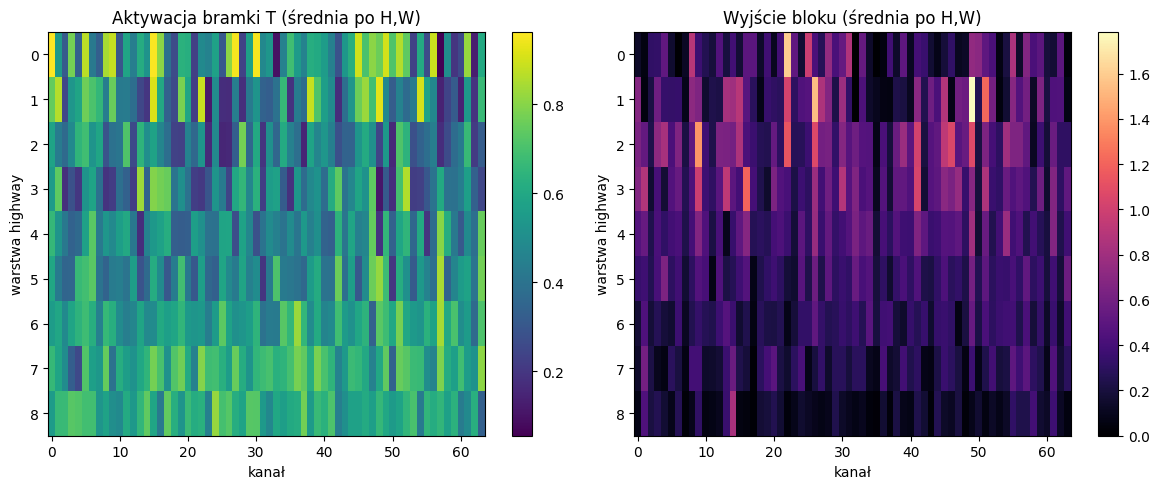

Średnia |zmiana aktywacji| między kolejnymi warstwami:
  warstwa  1: 0.3761
  warstwa  2: 0.3899
  warstwa  3: 0.3440
  warstwa  4: 0.3133
  warstwa  5: 0.2648
  warstwa  6: 0.2079
  warstwa  7: 0.2180
  warstwa  8: 0.1703


In [12]:
# 2) Aktywacje bramek i wyjścia bloków dla jednej próbki
@torch.no_grad()
def dump_activations(model, x):
    """Zwraca aktywacje bramek i wyjścia każdej warstwy highway.
    Kształt: (L, B, C, H, W)."""
    acts, outs = [], []
    x = F.relu(model.stem(x))
    for hw in model.highways:
        h = hw.activation(hw.H(x))
        t = torch.sigmoid(hw.T(x))
        outs.append(x.clone())
        acts.append(t.clone())
        x = h * t + x * (1 - t)
    return torch.stack(acts), torch.stack(outs)

x_sample, _ = test_set[0]
x_sample = x_sample.unsqueeze(0).to(device)
acts, outs = dump_activations(model, x_sample)

# Uśredniamy po batchu i wymiarach przestrzennych -> (L, C)
# To odpowiada Figure 2 z paperu: y = warstwa, x = kanał/blok
gate_activity = acts[:, 0].mean(dim=(2, 3)).cpu().numpy()   # (9, 64)
out_activity  = outs[:, 0].mean(dim=(2, 3)).cpu().numpy()   # (9, 64)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im0 = axes[0].imshow(gate_activity, aspect='auto', cmap='viridis')
axes[0].set_title("Aktywacja bramki T (średnia po H,W)")
axes[0].set_xlabel("kanał"); axes[0].set_ylabel("warstwa highway")
plt.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(out_activity, aspect='auto', cmap='magma')
axes[1].set_title("Wyjście bloku (średnia po H,W)")
axes[1].set_xlabel("kanał"); axes[1].set_ylabel("warstwa highway")
plt.colorbar(im1, ax=axes[1])

plt.tight_layout(); plt.show()

# 3) „Pasmowość” wyjść — jak mało zmienia się sygnał między warstwami
diffs = (outs[1:] - outs[:-1]).abs().mean(dim=(1, 2, 3, 4)).cpu().numpy()
print("Średnia |zmiana aktywacji| między kolejnymi warstwami:")
for i, d in enumerate(diffs, 1):
    print(f"  warstwa {i:2d}: {d:.4f}")